This is how we'll create data augmentations for our project. We can use the albumentations library to create many augmentations that go beyond the scope of just Keras.

In [2]:
%conda install -c conda-forge "opencv" "libprotobuf" --force-reinstall
%conda update -c conda-forge --all

2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.10.0

Please update conda by running

    $ conda update -n base -c defaults conda



## Package Plan ##

  environment location: /opt/miniconda3/envs/fml

  added / updated specs:
    - libprotobuf
    - opencv





Preparing transaction: done
Verifying transaction: done
Executing transaction: done

Note: you may need to restart the kernel to use updated packages.
2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.10.0

Please update conda by running

    $ conda update -n base -c defaults conda



## Package Plan ##

  environment location: /opt/miniconda3/envs/fml


The following packages will be 

In [11]:
import glob, os
import numpy as np
import cv2
import albumentations as A
import keras
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [19]:
IMG_SIZE = 224
BATCH_SIZE = 32
DATA_DIR = "data"
SEED = 33541943

CLASS_NAMES = {
    0: "Classroom",
    1: "Library",
    2: "Cafeteria",
    3: "Parking Area",
    4: "Outdoor Campus Area"
}

In [6]:
X = np.load(f"{DATA_DIR}/data_train.npy")
y = np.load(f"{DATA_DIR}/labels_train.npy")

X = X.reshape(-1, 224, 224, 3)
print(X.shape, X.dtype, y.shape)

(627, 224, 224, 3) uint8 (627,)


In [21]:
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.20, stratify=y_trval, random_state=SEED)

for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    counts = [(CLASS_NAMES[c],int((labels == c).sum())) for c in CLASS_NAMES.keys()]
    print(f"{name:5s} {len(labels):4d}  per class: {counts}")

train  400  per class: [('Classroom', 75), ('Library', 83), ('Cafeteria', 78), ('Parking Area', 81), ('Outdoor Campus Area', 83)]
val    101  per class: [('Classroom', 19), ('Library', 21), ('Cafeteria', 20), ('Parking Area', 20), ('Outdoor Campus Area', 21)]
test   126  per class: [('Classroom', 23), ('Library', 26), ('Cafeteria', 25), ('Parking Area', 26), ('Outdoor Campus Area', 26)]


In [38]:
# Right now, we randomly choose different transformations to apply together. We can change this to be one transformation of each type for each image and see if this improves performance

train_aug = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.5, 1.0), ratio=(0.85, 1.15)),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.1),
    # Types of distortion
    A.OneOf([
        A.Affine(scale=(0.9, 1.1), translate_percent=(-0.08, 0.08), rotate=(-20, 20), shear=(-8, 8)),
        A.Perspective(scale=(0.03, 0.08)),
        A.ElasticTransform(alpha=30, sigma=6),
        A.GridDistortion(),
        A.OpticalDistortion(),
    ], p=0.5),
    # Color differences
    A.OneOf([
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=25, val_shift_limit=15),
        A.RGBShift(r_shift_limit=15, g_shift_limit=15, b_shift_limit=15),
        A.ToGray(),
    ], p=0.5),
    # Brightness differneces
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25),
        A.RandomGamma(gamma_limit=(70, 130)),
        A.CLAHE(),
    ], p=0.4),
    # Blurring
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5)),
        A.MotionBlur(blur_limit=5),
        A.MedianBlur(blur_limit=5),
        A.Defocus(),
    ], p=0.25),
    # Sharpening
    A.OneOf([A.Sharpen(), A.Emboss()], p=0.15),
    # Noise
    A.OneOf([A.GaussNoise(), A.ISONoise(), A.MultiplicativeNoise()], p=0.25),
    # Weather
    A.OneOf([
        A.RandomRain(), A.RandomFog(), A.RandomSnow(), A.RandomSunFlare(), A.RandomShadow(),
    ], p=0.15),
    A.ImageCompression(p=0.2),
    A.CoarseDropout(p=0.2),
])

eval_aug = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])

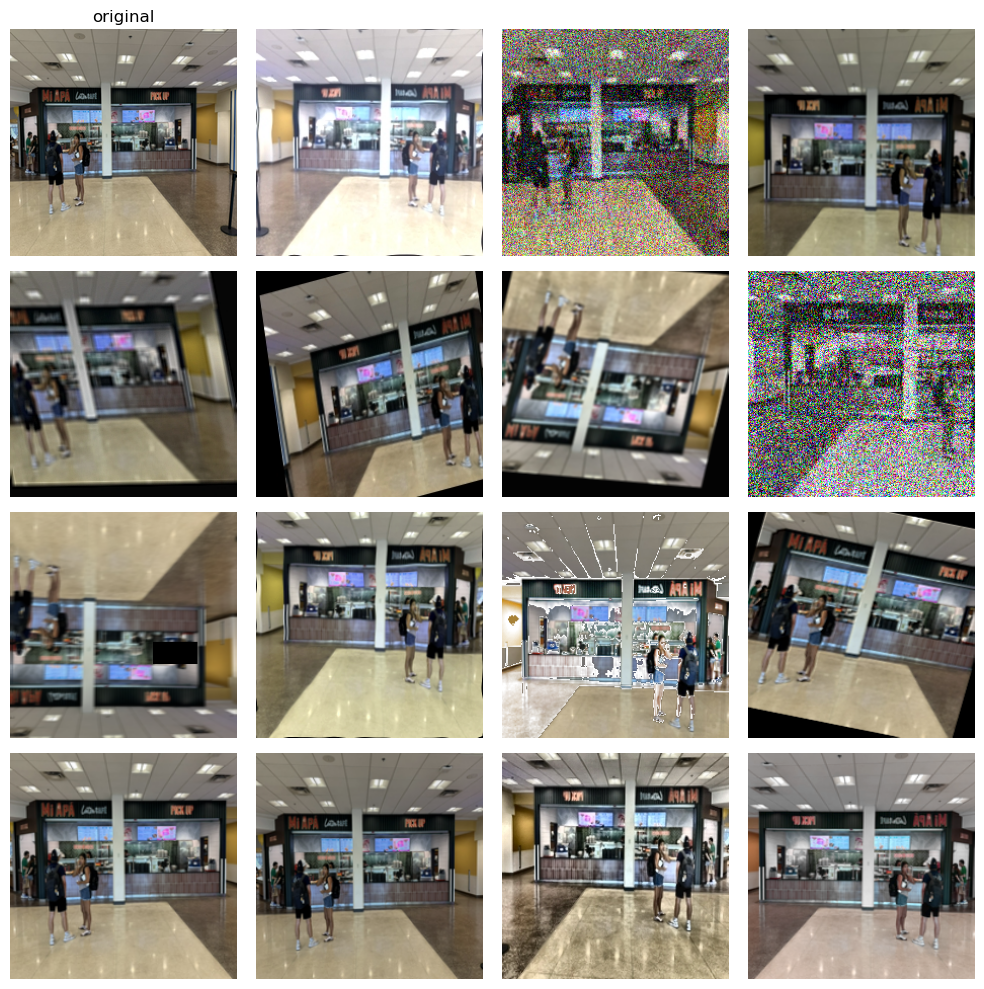

In [39]:
# Generates a random group of images transformations

img = X_train[np.random.randint(len(X_train))]
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes[0, 0].imshow(eval_aug(image=img)["image"]); axes[0, 0].set_title("original")
for ax in axes.flat[1:]:
    ax.imshow(train_aug(image=img)["image"])
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

We can play around with these percentages. Also, we can make a common class or function to generate augmentations for each model.

Keras models will have to build a new set of augmentations for each epoch (val and test datasets will not be augmented)
Sklearn will have to build a set number of copies for each image beforehand.